<a href="https://colab.research.google.com/github/kaixing189/MSSP607/blob/main/Case_Study_1_Academic_Performance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# MSSP607 Case Study Report Assignment 1
## Academic Performance and Equity Among Engineering Students

**Student:** Kai Xing  
**Role:** Analyst for the Department of Education




## 1. Load the workbook from the MSSP607 GitHub repository

The dataset is stored at:

```text
MSSP607/data/data_academic_performance (2).xlsx
```




In [1]:

from pathlib import Path
import os
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

REPO_DIR = Path("/content/MSSP607")
PUBLIC_REPO_URL = "https://github.com/kaixing189/MSSP607.git"

if not REPO_DIR.exists():
    try:
        subprocess.run(
            ["git", "clone", PUBLIC_REPO_URL, str(REPO_DIR)],
            check=True,
            capture_output=True,
            text=True
        )
        print("Repository cloned successfully.")
    except subprocess.CalledProcessError:
        from google.colab import userdata
        token = userdata.get("Git_Key")
        if token is None:
            raise RuntimeError(
                "The repository could not be cloned and Git_Key is not available in Colab Secrets."
            )
        private_url = f"https://{token}@github.com/kaixing189/MSSP607.git"
        subprocess.run(
            ["git", "clone", private_url, str(REPO_DIR)],
            check=True,
            capture_output=True,
            text=True
        )
        print("Private repository cloned successfully using Git_Key.")
else:
    print("Repository already exists in this Colab session.")

DATA_PATH = REPO_DIR / "data" / "data_academic_performance (2).xlsx"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at: {DATA_PATH}")

xls = pd.ExcelFile(DATA_PATH)
print("Workbook sheets:", xls.sheet_names)

df = pd.read_excel(DATA_PATH, sheet_name="SABER11_SABERPRO")

print("Dataset shape:", df.shape)
df.head()


Repository cloned successfully.
Workbook sheets: ['Citation', 'Description of Categorical', 'Description of Numerical', 'SABER11_SABERPRO']
Dataset shape: (12411, 45)


,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,...,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,...,71,93,79,181,180,91,5,4,2,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,...,86,98,78,201,182,92,5,4,4,4
2,SB11201210005154,M,Not sure,Not sure,Independent,Home,Stratum 2,Level 2,Five,NaN,...,18,43,22,113,113,7,1,1,1,1
3,SB11201210007504,F,Not sure,Not sure,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,76,80,48,137,157,67,4,3,2,2
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,...,98,100,71,189,198,98,5,4,4,2



**Expected result:** the analysis sheet contains **12,411 student records**. The source workbook may contain a blank column, so the exact number of imported columns can depend on the workbook layout.


## 2. Numerical summary of the main assessment variables

In [2]:

numeric_cols = [
    "MAT_S11", "CR_S11", "CC_S11", "BIO_S11", "ENG_S11",
    "QR_PRO", "CR_PRO", "CC_PRO", "ENG_PRO", "WC_PRO",
    "FEP_PRO", "G_SC"
]

numeric_summary = df[numeric_cols].describe().T[
    ["count", "mean", "std", "min", "50%", "max"]
]
numeric_summary = numeric_summary.rename(columns={"50%": "median"})

numeric_summary.round(2)


,count,mean,std,min,median,max
MAT_S11,12411.0,64.32,11.87,26.0,64.0,100.0
CR_S11,12411.0,60.78,10.03,24.0,61.0,100.0
CC_S11,12411.0,60.71,10.12,0.0,60.0,100.0
BIO_S11,12411.0,63.95,11.16,11.0,64.0,100.0
ENG_S11,12411.0,61.80,14.30,26.0,59.0,100.0
QR_PRO,12411.0,77.42,22.67,1.0,85.0,100.0
CR_PRO,12411.0,62.20,27.67,1.0,67.0,100.0
CC_PRO,12411.0,59.19,28.99,1.0,65.0,100.0
ENG_PRO,12411.0,67.50,25.50,1.0,74.0,100.0
WC_PRO,12411.0,53.70,30.00,0.0,56.0,100.0



The global assessment score (`G_SC`) has a mean of approximately **162.71**, a median of **163**, and a standard deviation of approximately **23.11**. Observed global scores range from **37 to 247**.


## 3. Parental education and student outcomes

In [3]:

# Clean parental-education categories.
# We exclude numeric/string 0 and "Not sure" because they do not provide a usable ordered education level.

def clean_parent_education(data, column):
    values_as_text = data[column].astype(str).str.strip()
    invalid = values_as_text.str.lower().isin(["0", "not sure", "nan"])
    return data.loc[~invalid].copy()

mother = clean_parent_education(df, "EDU_MOTHER")
father = clean_parent_education(df, "EDU_FATHER")

mother_summary = (
    mother.groupby("EDU_MOTHER")["G_SC"]
    .agg(["count", "mean", "std", "median"])
    .sort_values("mean", ascending=False)
)

father_summary = (
    father.groupby("EDU_FATHER")["G_SC"]
    .agg(["count", "mean", "std", "median"])
    .sort_values("mean", ascending=False)
)

print("Mother's education:")
display(mother_summary.round(2))

print("\nFather's education:")
display(father_summary.round(2))


Mother's education:


,count,mean,std,median
EDU_MOTHER,,,,
Postgraduate education,997,175.64,22.12,178.0
Complete professional education,3059,168.85,22.98,170.0
Incomplete Professional Education,502,166.69,22.93,168.0
Complete technique or technology,1495,163.24,21.94,163.0
Incomplete technical or technological,341,161.88,20.74,164.0
Complete Secundary,3106,158.47,21.95,159.0
Incomplete Secundary,1056,155.67,21.93,156.0
Complete primary,713,155.34,22.01,155.0
Incomplete primary,541,154.85,21.64,155.0



Father's education:


,count,mean,std,median
EDU_FATHER,,,,
Postgraduate education,1085,176.99,21.73,179.0
Complete professional education,3016,167.77,23.03,169.0
Incomplete Professional Education,425,166.92,22.69,168.0
Complete technique or technology,1194,164.03,22.17,164.0
Incomplete technical or technological,277,162.10,21.88,162.0
Complete Secundary,2843,158.79,22.11,159.0
Ninguno,123,156.63,23.19,159.0
Incomplete Secundary,1091,156.54,21.74,157.0
Incomplete primary,735,155.73,20.94,156.0


In [4]:

def one_way_eta_squared(data, group_col, outcome_col):
    groups = [
        group[outcome_col].dropna().values
        for _, group in data.groupby(group_col)
    ]
    f_stat, p_value = stats.f_oneway(*groups)

    grand_mean = data[outcome_col].mean()
    ss_between = sum(
        len(group) * (group.mean() - grand_mean) ** 2
        for group in groups
    )
    ss_total = ((data[outcome_col] - grand_mean) ** 2).sum()
    eta_sq = ss_between / ss_total

    return f_stat, p_value, eta_sq

mother_f, mother_p, mother_eta = one_way_eta_squared(
    mother, "EDU_MOTHER", "G_SC"
)
father_f, father_p, father_eta = one_way_eta_squared(
    father, "EDU_FATHER", "G_SC"
)

print(f"Mother education: F = {mother_f:.2f}, p = {mother_p:.4g}, eta-squared = {mother_eta:.3f}")
print(f"Father education: F = {father_f:.2f}, p = {father_p:.4g}, eta-squared = {father_eta:.3f}")


Mother education: F = 106.68, p = 5.53e-193, eta-squared = 0.075
Father education: F = 107.30, p = 6.158e-194, eta-squared = 0.077



### Answer to Question 1

Parental education is clearly associated with global academic performance.

Students whose mothers have postgraduate education average about **175.64** on `G_SC`, compared with about **158.47** for students whose mothers completed secondary education. Students whose fathers have postgraduate education average about **176.99**, compared with about **158.79** for complete secondary education.

The one-way comparisons indicate that maternal and paternal education are each associated with roughly **7.5% to 7.7%** of the observed variation in `G_SC`. This is a meaningful association, but it should not be interpreted as a causal effect because parental education is related to income, school type, academic preparation, and other background factors.


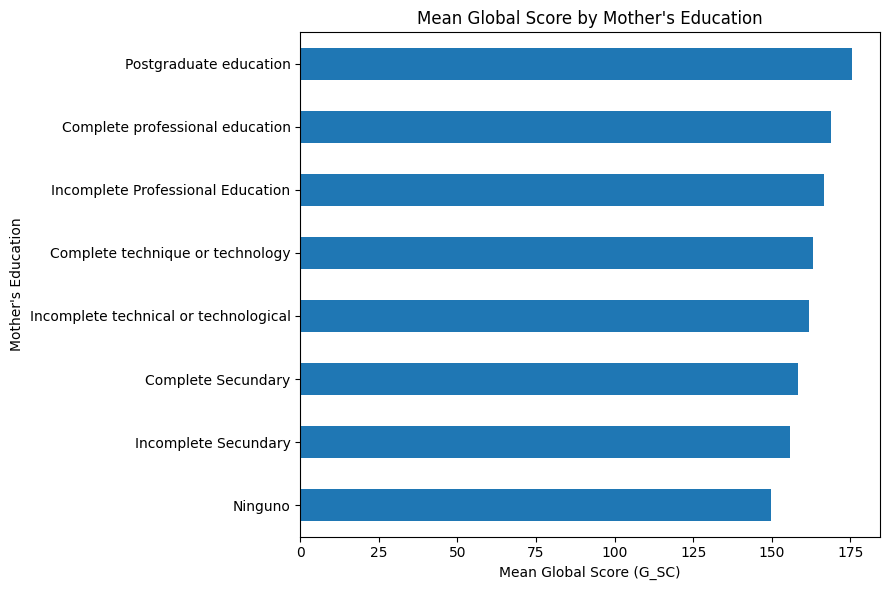

In [5]:

# Ordered display labels for mother's education
mother_order = [
    "Ninguno",
    "Incomplete primary",
    "Complete primary",
    "Incomplete Secundary",
    "Complete Secundary",
    "Incomplete technical or technological",
    "Complete technique or technology",
    "Incomplete Professional Education",
    "Complete professional education",
    "Postgraduate education"
]

mother_plot = (
    mother.groupby("EDU_MOTHER")["G_SC"].mean()
    .reindex(mother_order)
    .dropna()
)

ax = mother_plot.plot(kind="barh", figsize=(9, 6))
ax.set_title("Mean Global Score by Mother's Education")
ax.set_xlabel("Mean Global Score (G_SC)")
ax.set_ylabel("Mother's Education")
plt.tight_layout()
plt.show()


## 4. Socioeconomic stratum

In [6]:

# Remove the unusable stratum category 0.
stratum_text = df["STRATUM"].astype(str).str.strip()
stratum = df.loc[~stratum_text.isin(["0", "nan"])].copy()

stratum_order = [f"Stratum {i}" for i in range(1, 7)]

stratum_summary = (
    stratum.groupby("STRATUM")["G_SC"]
    .agg(["count", "mean", "std", "median"])
    .reindex(stratum_order)
)

display(stratum_summary.round(2))

stratum_f, stratum_p, stratum_eta = one_way_eta_squared(
    stratum, "STRATUM", "G_SC"
)

print(f"ANOVA F = {stratum_f:.2f}")
print(f"p-value = {stratum_p:.4g}")
print(f"eta-squared = {stratum_eta:.3f}")


,count,mean,std,median
STRATUM,,,,
Stratum 1,1709,152.35,21.94,152.0
Stratum 2,4029,158.20,22.28,158.0
Stratum 3,4045,163.82,21.69,164.0
Stratum 4,1578,172.00,21.47,174.0
Stratum 5,633,177.39,21.54,179.0
Stratum 6,403,181.51,21.88,184.0


ANOVA F = 286.06
p-value = 1.426e-290
eta-squared = 0.103



### Answer to Question 2

Socioeconomic stratum shows the strongest ordered pattern among the required comparisons.

Mean `G_SC` rises from approximately **152.35 in Stratum 1** to **181.51 in Stratum 6**, a gap of about **29.16 points**. The mean rises at every stratum level. The one-way ANOVA is statistically significant and the eta-squared is approximately **0.103**, so socioeconomic stratum is associated with about **10.3%** of the observed variation in global scores in this unadjusted comparison.

Therefore, **Stratum 6 performs best on average**, while Stratum 1 has the lowest average score.


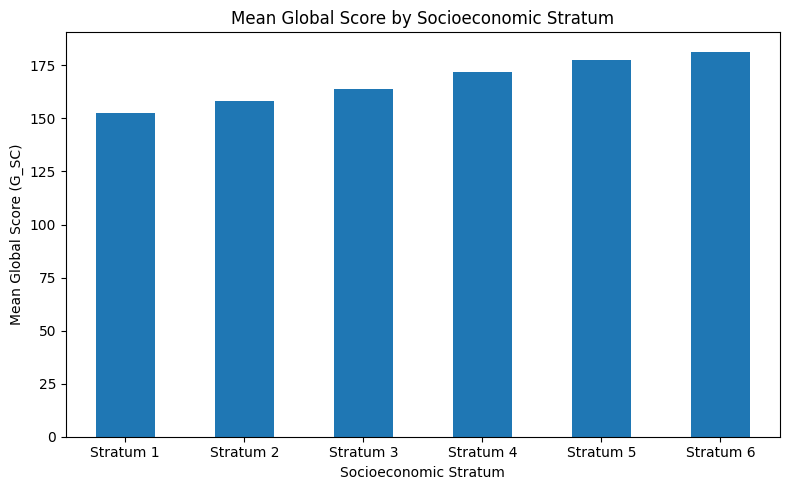

In [7]:

ax = stratum_summary["mean"].plot(kind="bar", figsize=(8, 5))
ax.set_title("Mean Global Score by Socioeconomic Stratum")
ax.set_xlabel("Socioeconomic Stratum")
ax.set_ylabel("Mean Global Score (G_SC)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 5. Gender and the global assessment

In [8]:

gender_summary = (
    df.groupby("GENDER")["G_SC"]
    .agg(["count", "mean", "std", "median"])
)

display(gender_summary.round(2))

male = df.loc[df["GENDER"] == "M", "G_SC"].dropna()
female = df.loc[df["GENDER"] == "F", "G_SC"].dropna()

t_stat, p_value = stats.ttest_ind(male, female, equal_var=False)

pooled_sd = np.sqrt(
    ((len(male) - 1) * male.var(ddof=1) +
     (len(female) - 1) * female.var(ddof=1))
    / (len(male) + len(female) - 2)
)

cohen_d = (male.mean() - female.mean()) / pooled_sd

print(f"Male mean: {male.mean():.2f}")
print(f"Female mean: {female.mean():.2f}")
print(f"Mean difference: {male.mean() - female.mean():.2f}")
print(f"Welch t-test p-value: {p_value:.4g}")
print(f"Cohen's d: {cohen_d:.3f}")


,count,mean,std,median
GENDER,,,,
F,5043,161.28,22.33,162.0
M,7368,163.69,23.58,164.0


Male mean: 163.69
Female mean: 161.28
Mean difference: 2.41
Welch t-test p-value: 7.785e-09
Cohen's d: 0.105



### Answer to Question 3

Male students average approximately **163.69** on the global assessment, while female students average approximately **161.28**. The difference is about **2.41 points**.

The difference is statistically significant in this large sample, but the standardized effect is small (**Cohen's d ≈ 0.105**). The overall gender difference is therefore much smaller than the socioeconomic differences.


GENDER,F,M
QR_PRO,71.89,81.20
CR_PRO,61.34,62.79
CC_PRO,58.57,59.61
ENG_PRO,66.53,68.16
WC_PRO,56.62,51.71
FEP_PRO,145.30,145.60
G_SC,161.28,163.69


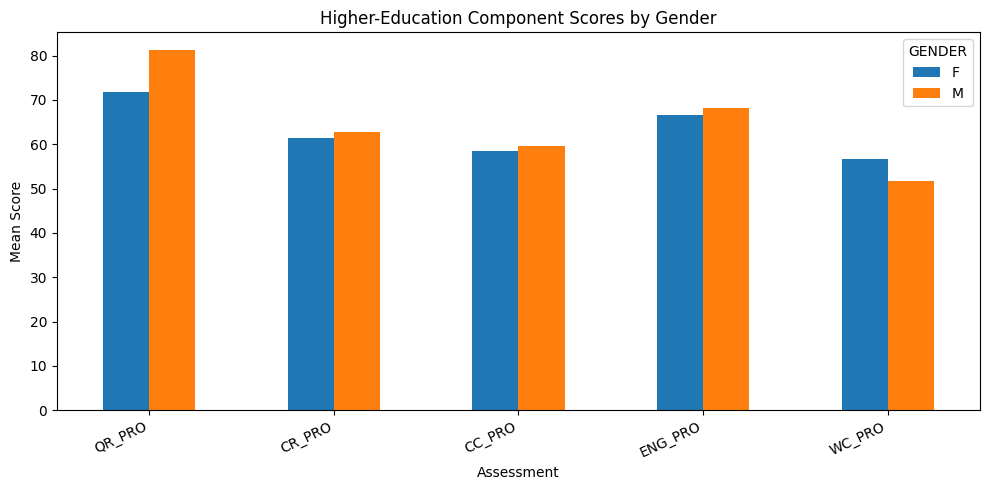

In [9]:

pro_components = ["QR_PRO", "CR_PRO", "CC_PRO", "ENG_PRO", "WC_PRO", "FEP_PRO", "G_SC"]

gender_components = df.groupby("GENDER")[pro_components].mean().T
display(gender_components.round(2))

# Plot comparable component scores only; FEP_PRO and G_SC use different scales.
plot_components = ["QR_PRO", "CR_PRO", "CC_PRO", "ENG_PRO", "WC_PRO"]

ax = gender_components.loc[plot_components].plot(
    kind="bar",
    figsize=(10, 5)
)
ax.set_title("Higher-Education Component Scores by Gender")
ax.set_xlabel("Assessment")
ax.set_ylabel("Mean Score")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()



The component results are more informative than the small global-score gap. Male students average higher in **Quantitative Reasoning** (about **81.20** versus **71.89**), while female students average higher in **Written Communication** (about **56.62** versus **51.71**). This supports skill-specific academic support rather than broad conclusions based only on gender.


## 6. Academic program comparison

,count,mean,std
ACADEMIC_PROGRAM,,,
CHEMICAL ENGINEERING,1000,176.70,18.69
ELECTRIC ENGINEERING,278,173.99,19.35
ELECTRONIC ENGINEERING,849,166.87,22.20
MECHANICAL ENGINEERING,1135,166.05,23.26
CIVIL ENGINEERING,3320,161.11,22.83
INDUSTRIAL ENGINEERING,5318,159.04,23.16


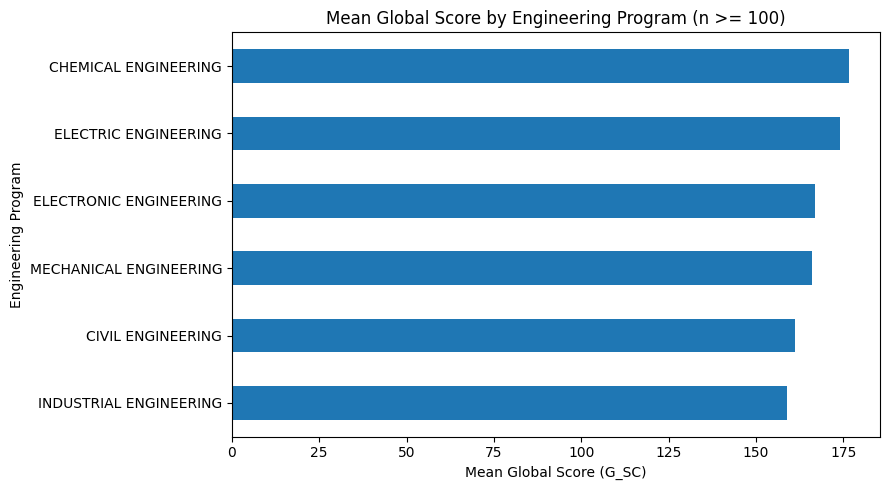

In [10]:

program_summary = (
    df.groupby("ACADEMIC_PROGRAM")["G_SC"]
    .agg(["count", "mean", "std"])
    .sort_values("mean", ascending=False)
)

# Avoid ranking very small groups.
program_large = program_summary.loc[program_summary["count"] >= 100]

display(program_large.round(2))

ax = program_large["mean"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)
ax.set_title("Mean Global Score by Engineering Program (n >= 100)")
ax.set_xlabel("Mean Global Score (G_SC)")
ax.set_ylabel("Engineering Program")
plt.tight_layout()
plt.show()



Among programs with at least 100 students, **Chemical Engineering** has the highest raw mean global score at approximately **176.70**, followed by **Electric Engineering** at approximately **173.99**.

These are descriptive comparisons. They should not be used as direct measures of program quality because programs may differ in student selection, prior academic achievement, institution, and socioeconomic composition.


## 7. Additional socioeconomic and resource indicators

In [11]:

additional_vars = ["SISBEN", "REVENUE", "SCHOOL_NAT", "INTERNET", "COMPUTER", "SEL_IHE"]

for column in additional_vars:
    print("\n", column)
    summary = (
        df.groupby(column)["G_SC"]
        .agg(["count", "mean", "std"])
        .sort_values("mean", ascending=False)
    )
    display(summary.round(2))



 SISBEN


,count,mean,std
SISBEN,,,
It is not classified by the SISBEN,7534,167.47,22.48
Esta clasificada en otro Level del SISBEN,96,166.05,22.51
Level 3,583,160.99,21.64
0,21,158.62,20.09
Level 2,2120,155.89,22.27
Level 1,2057,152.68,21.66



 REVENUE


,count,mean,std
REVENUE,,,
10 or more LMMW,718,183.67,20.72
Between 7 and less than 10 LMMW,509,176.18,19.96
Between 5 and less than 7 LMMW,973,170.86,21.79
0,279,169.72,22.64
Between 3 and less than 5 LMMW,2239,165.34,22.08
Between 2 and less than 3 LMMW,2783,160.94,21.63
Between 1 and less than 2 LMMW,3873,156.77,22.05
less than 1 LMMW,1037,153.31,22.01



 SCHOOL_NAT


...

,count,mean,std
INTERNET,,,
Yes,9752,164.92,22.86
No,2659,154.62,22.21



 COMPUTER


,count,mean,std
COMPUTER,,,
Yes,10174,164.20,23.12
No,2237,155.95,21.86



 SEL_IHE


,count,mean,std
SEL_IHE,,,
4,2692,178.85,20.18
3,834,164.82,17.21
2,7748,158.28,22.27
1,1137,153.14,20.61


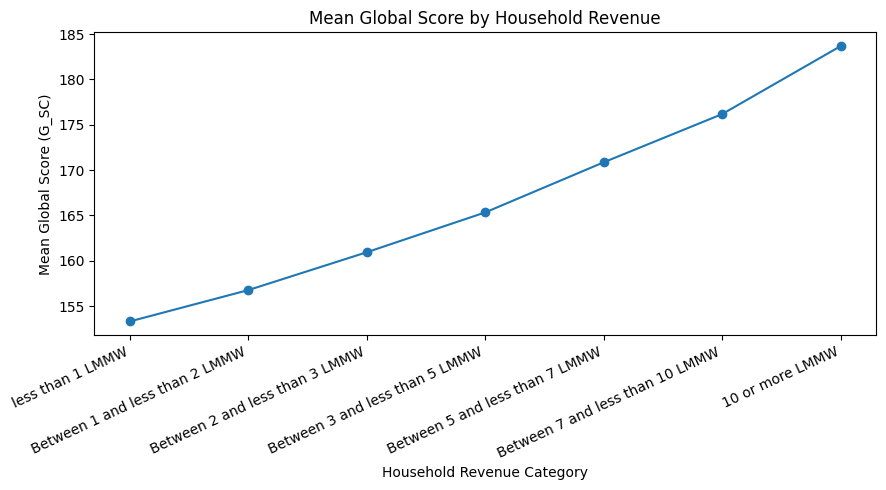

In [12]:

# Household revenue gradient, excluding the unusable category 0.
revenue_order = [
    "less than 1 LMMW",
    "Between 1 and less than 2 LMMW",
    "Between 2 and less than 3 LMMW",
    "Between 3 and less than 5 LMMW",
    "Between 5 and less than 7 LMMW",
    "Between 7 and less than 10 LMMW",
    "10 or more LMMW"
]

revenue_mean = (
    df.groupby("REVENUE")["G_SC"].mean()
    .reindex(revenue_order)
)

ax = revenue_mean.plot(marker="o", figsize=(9, 5))
ax.set_title("Mean Global Score by Household Revenue")
ax.set_xlabel("Household Revenue Category")
ax.set_ylabel("Mean Global Score (G_SC)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()



Several additional patterns reinforce the socioeconomic interpretation:

- Students with internet access average approximately **164.92**, compared with **154.62** for students without internet access.
- Students from private high schools average approximately **168.22**, compared with **156.53** for public high-school students.
- Household revenue shows a strong gradient, from about **153.31** among students in households below one LMMW to about **183.67** among students in households at 10 or more LMMW.


## 8. Relationship between high-school preparation and later global performance

In [13]:

s11_scores = ["MAT_S11", "CR_S11", "CC_S11", "BIO_S11", "ENG_S11"]

prior_correlations = (
    df[s11_scores + ["G_SC"]]
    .corr()["G_SC"]
    .drop("G_SC")
    .sort_values(ascending=False)
)

prior_correlations


,G_SC
BIO_S11,0.666635
ENG_S11,0.662169
CR_S11,0.653572
MAT_S11,0.643838
CC_S11,0.634900



The high-school academic measures are strongly related to later global performance. In the source analysis, correlations between the five S11 scores and `G_SC` are approximately **0.63 to 0.67**. This suggests that academic preparation before university is an important predictor of later performance and supports early bridge or transition programs.



## 9. Conclusions and recommendations

### Answer to Question 4

The most important finding is that the largest and most consistent performance gaps are socioeconomic rather than gender-based. Socioeconomic stratum, household revenue, internet access, school type, and parental education all show meaningful differences in average global scores.

The Department of Education should consider a **targeted equity and skill-specific support strategy**:

1. **Prioritize lower-resource students.** Use several indicators together, such as socioeconomic stratum, household revenue, SISBEN status, internet access, and school background.
2. **Provide early bridge support.** High-school achievement is strongly related to later performance, so transition programs and early tutoring may help prevent gaps from growing.
3. **Use skill-specific diagnostics.** The small overall gender gap hides larger differences in quantitative reasoning and written communication.
4. **Expand mentoring and academic navigation.** Lower parental education may identify students who have less family experience navigating higher education.
5. **Do not rank programs using raw averages alone.** Program comparisons should be adjusted for prior achievement and student background before being used for accountability.
6. **Pilot interventions and evaluate outcomes.** The current dataset is observational, so the analysis identifies associations rather than proving that any background characteristic causes higher or lower scores.


## 10. Final verification of key required results

In [16]:

# These checks make sure the notebook is using the intended dataset and reproducing the main findings.

assert len(df) == 12411
assert round(df["G_SC"].mean(), 2) == 162.71
assert round(df.loc[df["GENDER"] == "M", "G_SC"].mean(), 2) == 163.69
assert round(df.loc[df["GENDER"] == "F", "G_SC"].mean(), 2) == 161.28

assert round(stratum_summary.loc["Stratum 1", "mean"], 2) == 152.35
assert round(stratum_summary.loc["Stratum 6", "mean"], 2) == 181.51
assert abs(stratum_eta - 0.103) < 0.001

# Allow small rounding differences in parental-education eta-squared values.
assert 0.07 < mother_eta < 0.08
assert 0.07 < father_eta < 0.08

print("All required Case Study 1 results verified successfully.")


All required Case Study 1 results verified successfully.



## Source

De La Hoz, Enrique. *Data of Academic Performance Evolution for Engineering Students*. Mendeley Data, Version 1, 2020. https://doi.org/10.17632/83tcx8psxv.1
